In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori,association_rules

In [3]:
data=pd.read_csv("Order1.csv")
data.head(5)

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5,Item 6,Item 7,Item 8,Item 9,...,Item 23,Item 24,Item 25,Item 26,Item 27,Item 28,Item 29,Item 30,Item 31,Item 32
0,4,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,tropical fruit,yogurt,coffee,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,whole milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
data=data.drop('Item(s)',axis=1)
data.columns=data.columns.str.strip()
data.head(5)

,Item 1,Item 2,Item 3,Item 4,Item 5,Item 6,Item 7,Item 8,Item 9,Item 10,...,Item 23,Item 24,Item 25,Item 26,Item 27,Item 28,Item 29,Item 30,Item 31,Item 32
0,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tropical fruit,yogurt,coffee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,whole milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
transactions=[]
for i in range(len(data)):
    items=data.iloc[i].dropna().tolist()
    items=[item.strip() for item in items if str(item).strip()!=""]
    transactions.append(items)

print(transactions[:5])

[['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups'], ['tropical fruit', 'yogurt', 'coffee'], ['whole milk'], ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads'], ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']]


In [13]:
te=TransactionEncoder()
encoded_data=te.fit(transactions).transform(transactions)

df=pd.DataFrame(encoded_data,columns=te.columns_)
df.head(5)
df.shape

(9835, 169)

In [11]:
frequent_patterns=apriori(df,min_support=0.01,use_colnames=True)
print(frequent_patterns)

      support                                       itemsets
0    0.033452                                     (UHT-milk)
1    0.017692                                (baking powder)
2    0.052466                                         (beef)
3    0.033249                                      (berries)
4    0.026029                                    (beverages)
..        ...                                            ...
328  0.011998  (tropical fruit, root vegetables, whole milk)
329  0.014540          (yogurt, root vegetables, whole milk)
330  0.010473                     (yogurt, whole milk, soda)
331  0.015150           (yogurt, tropical fruit, whole milk)
332  0.010880       (yogurt, whipped/sour cream, whole milk)

[333 rows x 2 columns]


In [22]:
rules=association_rules(frequent_patterns,metric="confidence",min_threshold=0.4)
print(rules)

                          antecedents         consequents  antecedent support  \
0                              (beef)        (whole milk)            0.052466   
1                            (butter)        (whole milk)            0.055414   
2                       (butter milk)        (whole milk)            0.027961   
3                           (chicken)  (other vegetables)            0.042908   
4                           (chicken)        (whole milk)            0.042908   
..                                ...                 ...                 ...   
57               (rolls/buns, yogurt)        (whole milk)            0.034367   
58  (tropical fruit, root vegetables)        (whole milk)            0.021047   
59          (yogurt, root vegetables)        (whole milk)            0.025826   
60           (yogurt, tropical fruit)        (whole milk)            0.029283   
61       (yogurt, whipped/sour cream)        (whole milk)            0.020742   

    consequent support   su

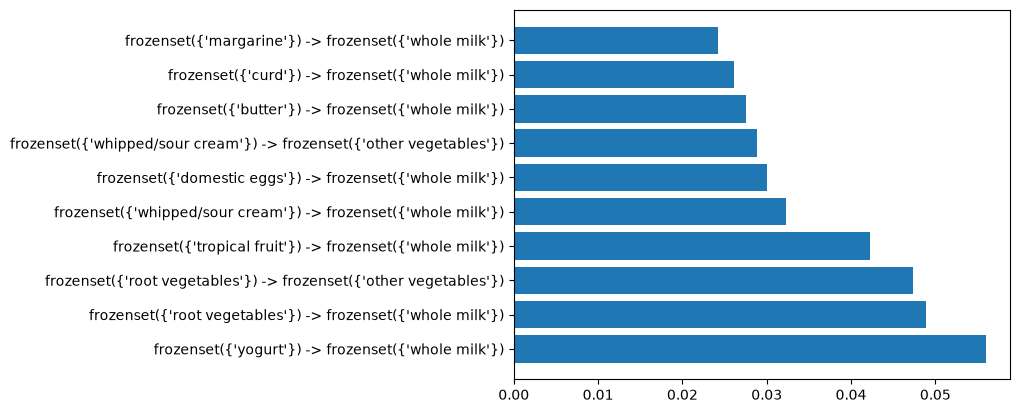

In [23]:
# visualization
top10=rules.sort_values(by='support',ascending=False).head(10)

labels=top10['antecedents'].astype(str)+' -> '+top10['consequents'].astype(str)

plt.barh(labels,top10['support'])
plt.show()

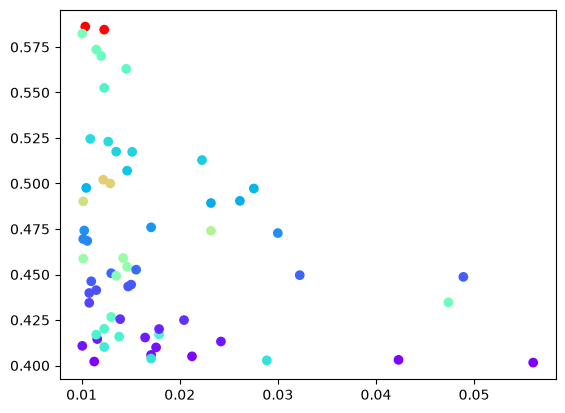

In [24]:
# support vs confidence
plt.scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap='rainbow')
plt.show()

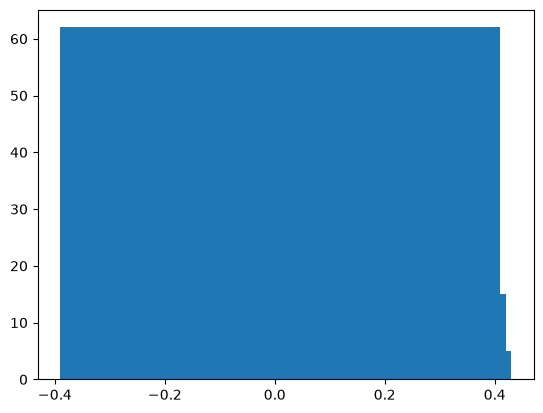

In [25]:
support_values=[0.01,0.02,0.03]
counts=[]

for val in support_values:
    count=(rules['support']>=val).sum()
    counts.append(count)

plt.bar(support_values,counts)
plt.show()